# Small tracking notebook

In this jupyter notebook we will see how to use OpenCV to track an object in a video. We'll first select the object (Region Of Interest) then track it through the frame and finally we' ll plot the evolution of the barycenter of the object with regard to the frame number.

## Import the used libraries
We'll need 
* OpenCV (cv2)
* tracking_tools to read the ROI
* matplotlib to do our plots
* IPython.display for the inline display of the tracked video in the notebook

In [1]:
import cv2
from IPython.display import display, clear_output
import numpy as np
import tracking_tools as tt
import matplotlib.pyplot as plt

## Choose the video file and select the ROI

In [2]:
video_path  = "Pendulum/pend.mov"  
bbox        = tt.select_ROI(video_path)

Select a ROI and then press SPACE or ENTER button!
Cancel the selection process by pressing c button!


2025-10-11 19:16:03.125 python[92027:5379360] +[IMKClient subclass]: chose IMKClient_Modern
2025-10-11 19:16:03.125 python[92027:5379360] +[IMKInputSession subclass]: chose IMKInputSession_Modern


## Initialise the tracker

The tracker is the **CSRT** tracker from OpenCV based on [@lukezicDiscriminativeCorrelationFilter2017] that we initialised based of the **bounding box** surrounding delimiting the ROI.

In [3]:
cap         = cv2.VideoCapture(video_path)
flag, frame = cap.read()

if hasattr(cv2, 'legacy'):
    tracker = cv2.legacy.TrackerCSRT_create()
else:
    tracker = cv2.TrackerCSRT_create()

tracker.init(frame, bbox)
positions   = []
frame_num   = 0


## Actual tracking
We now loop over the frame to perform the actual tracking and store the positino of the barycenter of the ROI for each frame.

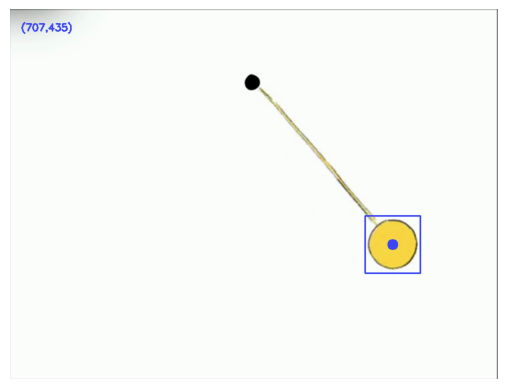

In [4]:
while True:
    frame_num +=1
    flag_read, frame = cap.read()
    if not flag_read:
        break
    flag_track, bbox = tracker.update(frame)
    if flag_track:
        x, y, w, h  = [int(v) for v in bbox]
        center_x    = x + w // 2
        center_y    = y + h // 2
        positions.append([frame_num, center_x, center_y])

        cv2.rectangle(frame, (x, y), (x + w, y + h), (245, 70, 58), 2)
        cv2.circle(frame, (center_x, center_y), int(0.1*min(h,w)), (245, 70, 58), -1)
        cv2.putText(frame, f"({center_x},{center_y})", (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (245, 70, 58), 2)
    else:
        cv2.putText(frame, "Lost", (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (247, 59, 218), 2)

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)  

    clear_output(wait=True)
    plt.imshow(rgb)
    plt.axis('off')
    plt.show()

cap.release()

## Post-processing

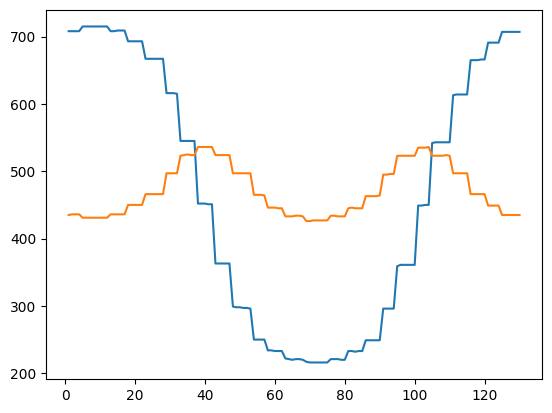

In [5]:
import numpy as np
plt.plot(np.array(positions)[:,0],np.array(positions)[:,1])
plt.plot(np.array(positions)[:,0],np.array(positions)[:,2])